# 0. Setup

In [10]:
# Basic libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.base import clone
from sklearn.preprocessing import OneHotEncoder
import re

# Evaluation Libraries
from sklearn.metrics import roc_auc_score

# LightGBM
import lightgbm as lgb
from lightgbm import LGBMClassifier
import optuna

# 1. Load All Final Aggregated Datasets

In [11]:
def load_data(data_path : str):
    df = pd.read_csv(f"{data_path}")

    return df

In [12]:
application_train_test = load_data("D:/4. Home Credit/Dataset/CSV/application_train_test_final_agg.csv")
previous_application = load_data("D:/4. Home Credit/Dataset/CSV/previous_application_final_agg.csv")
instalments_payment = load_data("D:/4. Home Credit/Dataset/CSV/instalments_payment_agg_final.csv")
pos_card_balance = load_data("D:/4. Home Credit/Dataset/CSV/pos_cash_balanced_agg_final.csv")
card_balance = load_data("D:/4. Home Credit/Dataset/CSV/card_balanced_agg_final.csv")
bureau = load_data("D:/4. Home Credit/Dataset/CSV/bureau_agg_final.csv")

# 2. Merge All Datasets Together

In [13]:
# Get full data
full_data = application_train_test.copy()

# Merging
full_data = full_data.merge(
    previous_application,
    on="SK_ID_CURR",
    how="left"
)

full_data = full_data.merge(
    instalments_payment,
    on="SK_ID_CURR",
    how="left"
)

full_data = full_data.merge(
    pos_card_balance,
    on="SK_ID_CURR",
    how="left"
)

full_data = full_data.merge(
    card_balance,
    on="SK_ID_CURR",
    how="left"
)

full_data = full_data.merge(
    bureau,
    on="SK_ID_CURR",
    how="left"
)

print("Final merged shape:", full_data.shape)
full_data.head()

Final merged shape: (356255, 586)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,BUREAU_CLOSED_AMT_CREDIT_SUM_SUM,BUREAU_CLOSED_AMT_CREDIT_SUM_DEBT_SUM,BUREAU_CLOSED_AMT_CREDIT_SUM_OVERDUE_SUM,BUREAU_CLOSED_AMT_ANNUITY_SUM,BUREAU_CLOSED_DEBT_TO_CREDIT_RATIO_MEAN,BUREAU_CLOSED_CREDIT_DAY_OVERDUE_MAX,BUREAU_TOTAL_DEBT_TO_CREDIT,BUREAU_ACTIVE_DEBT_TO_CREDIT,BUREAU_ACTIVE_RATIO,BUREAU_LIMIT_USAGE
0,100002,1.0,Cash loans,M,N,Y,202500.0,406597.5,24700.5,351000.0,...,383067.0,0.0,0.0,0.0,0.0,0.0,0.284121,0.50993,0.25,7.683162
1,100003,0.0,Cash loans,F,N,N,270000.0,1293502.5,35698.5,1129500.0,...,207400.5,0.0,0.0,0.0,0.0,0.0,0.000000,0.00000,0.25,0.000000
2,100004,0.0,Revolving loans,M,Y,Y,67500.0,135000.0,6750.0,135000.0,...,189037.8,0.0,0.0,0.0,0.0,0.0,0.000000,NaN,NaN,0.000000
3,100006,0.0,Cash loans,F,N,Y,135000.0,312682.5,29686.5,297000.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0.0,Cash loans,M,N,Y,121500.0,513000.0,21865.5,513000.0,...,146250.0,0.0,0.0,0.0,0.0,0.0,0.000000,NaN,NaN,0.000000


# 3. Preprocessing

## 3.1 Convert Categorical Columns

In [14]:
# Categorical cols
cat_cols = full_data.select_dtypes(include = ['object','string']).columns

for col in cat_cols:
    full_data[col] = full_data[col].astype("category")

## 3.2 Days Columns

In [15]:
special_day = [
    'APPLICATION_DAYS_BIRTH',
    'APPLICATION_DAYS_EMPLOYED',
    'APPLICATION_DAYS_REGISTRATION',
    'APPLICATION_DAYS_ID_PUBLISH'
]

for col in special_day:
    full_data[col] = abs(full_data[col])


# 4. Train, Test Split (80 - 20) 

In [16]:
train = full_data[full_data['TARGET'].notna()].copy()
test = full_data[full_data['TARGET'].isna()].copy()

X = train.drop(columns = ['SK_ID_CURR','TARGET']).replace([np.inf, -np.inf], np.nan)
y = train['TARGET']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, stratify = y, random_state = 42)

## 5. Cleaning Column Name

In [17]:
X_train.columns = [re.sub(r"[^A-Za-z0-9_]", "_", col) for col in X_train.columns]
X_test.columns = [re.sub(r"[^A-Za-z0-9_]", "_", col) for col in X_test.columns]

# 6. Train LightGBM Model

### 6.1 Cross Validation

In [18]:
cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)

lgbm = LGBMClassifier(
    boosting_type = 'gbdt',
    data_sample_strategy = 'goss',
    top_rate = 0.2,
    other_rate = 0.1,
    n_estimators = 20000,
    learning_rate = 0.01,
    num_leaves = 31,
    max_depth = 8,
    min_child_samples = 120,
    reg_alpha = 2.5,
    reg_lambda = 3.5,
    colsample_bytree = 0.15,
    subsample = 1.0,
    subsample_freq = 0,
    random_state = 42,
    verbosity = -1,
    n_jobs = -1
)

oof_preds = np.zeros(len(X_train))
test_preds = np.zeros(len(X_test))
fold_scores = []
best_iters = []

for fold, (tr_idx, val_idx) in enumerate(cv.split(X_train, y_train), 1):
    X_tr = X_train.iloc[tr_idx]
    X_val = X_train.iloc[val_idx]
    y_tr = y_train.iloc[tr_idx]
    y_val = y_train.iloc[val_idx]

    model = clone(lgbm)

    model.set_params(objective = "binary",metric = "auc")

    model.fit(
        X_tr, 
        y_tr,
        eval_set=[(X_val, y_val)],
        eval_metric = "auc",
        callbacks=[
            lgb.early_stopping(200, first_metric_only=True),
            lgb.log_evaluation(500)
        ]
    )
    best_iters.append(model.best_iteration_)

    val_pred = model.predict_proba(X_val)[:, 1]
    oof_preds[val_idx] = val_pred

    test_preds += model.predict_proba(X_test)[:, 1] / 5

    auc = roc_auc_score(y_val, val_pred)
    fold_scores.append(auc)

    print(f"Fold {fold}: AUC={auc:.6f}")
    print(f"Best iteration: {model.best_iteration_}")

print("Mean CV AUC:", np.mean(fold_scores))
print("Std CV AUC:", np.std(fold_scores))
print("Full OOF AUC:", roc_auc_score(y_train, oof_preds))
print("Holdout AUC:", roc_auc_score(y_test, test_preds))

c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 200 rounds
[500]	valid_0's auc: 0.776205
[1000]	valid_0's auc: 0.785871
[1500]	valid_0's auc: 0.789219
[2000]	valid_0's auc: 0.790831
[2500]	valid_0's auc: 0.791664
[3000]	valid_0's auc: 0.792103
[3500]	valid_0's auc: 0.792278
[4000]	valid_0's auc: 0.792532
Early stopping, best iteration is:
[4015]	valid_0's auc: 0.792582
Evaluated only: auc
Fold 1: AUC=0.792582
Best iteration: 4015


c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 200 rounds
[500]	valid_0's auc: 0.779344
[1000]	valid_0's auc: 0.788639
[1500]	valid_0's auc: 0.791719
[2000]	valid_0's auc: 0.793034
[2500]	valid_0's auc: 0.793717
Early stopping, best iteration is:
[2472]	valid_0's auc: 0.793742
Evaluated only: auc
Fold 2: AUC=0.793742
Best iteration: 2472


c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 200 rounds
[500]	valid_0's auc: 0.781737
[1000]	valid_0's auc: 0.789555
[1500]	valid_0's auc: 0.792426
[2000]	valid_0's auc: 0.794038
[2500]	valid_0's auc: 0.794742
[3000]	valid_0's auc: 0.795228
Early stopping, best iteration is:
[3164]	valid_0's auc: 0.795236
Evaluated only: auc
Fold 3: AUC=0.795236
Best iteration: 3164


c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 200 rounds
[500]	valid_0's auc: 0.78375
[1000]	valid_0's auc: 0.792127
[1500]	valid_0's auc: 0.795238
[2000]	valid_0's auc: 0.796819
[2500]	valid_0's auc: 0.797456
[3000]	valid_0's auc: 0.797669
[3500]	valid_0's auc: 0.797802
Early stopping, best iteration is:
[3433]	valid_0's auc: 0.797835
Evaluated only: auc
Fold 4: AUC=0.797835
Best iteration: 3433


c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 200 rounds
[500]	valid_0's auc: 0.780667
[1000]	valid_0's auc: 0.790016
[1500]	valid_0's auc: 0.793219
[2000]	valid_0's auc: 0.794836
[2500]	valid_0's auc: 0.795556
[3000]	valid_0's auc: 0.795885
Early stopping, best iteration is:
[3149]	valid_0's auc: 0.795992
Evaluated only: auc
Fold 5: AUC=0.795992
Best iteration: 3149
Mean CV AUC: 0.7950774141954721
Std CV AUC: 0.0018150310447616446
Full OOF AUC: 0.7950250505239098
Holdout AUC: 0.7982633074415956


### 6.2 Optuna

In [19]:
# X_full = train.drop(columns=['SK_ID_CURR', 'TARGET'])
# X_full.replace([np.inf, -np.inf], np.nan, inplace=True)
# X_full.columns = [re.sub(r"[^A-Za-z0-9_]", "_", col) for col in X_train.columns]
# y_full = train['TARGET']

# def objective(trial):
#     params = {
#         'n_estimators': 3000,        # cao cố định, để early stopping tự quyết
#         'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.05, log = True),
#         'num_leaves': trial.suggest_int('num_leaves', 15, 127),
#         'max_depth': trial.suggest_int('max_depth', -1, 12),
#         'min_child_samples': trial.suggest_int('min_child_samples', 50, 200),
#         'reg_alpha': trial.suggest_float('reg_alpha', 0.01, 1, log=True),
#         'reg_lambda': trial.suggest_float('reg_lambda', 0.01, 1, log=True),
#         'subsample': trial.suggest_float('subsample', 0.5, 1.0),
#         'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
#         'subsample_freq': 1,
#         'random_state': 42,
#         'verbose': -1
#     }

#     cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)
#     scores = []

#     for train_idx, val_idx in cv.split(X_full, y_full):
#         X_tr, X_val = X_full.iloc[train_idx], X_full.iloc[val_idx]
#         y_tr, y_val = y_full.iloc[train_idx], y_full.iloc[val_idx]

#         model = LGBMClassifier(**params)
#         model.fit(
#             X_tr, y_tr,
#             eval_set=[(X_val, y_val)],
#             eval_metric='auc',
#             callbacks=[
#                 lgb.early_stopping(stopping_rounds=100, verbose=False),
#                 lgb.log_evaluation(period=-1)
#             ]
#         )

#         preds = model.predict_proba(X_val)[:, 1]
#         scores.append(roc_auc_score(y_val, preds))

#     return np.mean(scores)


# study = optuna.create_study(direction='maximize')
# study.optimize(objective, n_trials=50, show_progress_bar=True)

# print("Best AUC:", study.best_value)
# print("Best params:", study.best_params)

In [20]:
# Submission: K-fold on all labeled rows, each fold early-stops on its own validation set,
# then average the fold models' predictions on Kaggle test -> no need to guess the number of trees.

from pathlib import Path

lgbm = LGBMClassifier(
    boosting_type = 'gbdt',
    data_sample_strategy = 'goss',
    top_rate = 0.2,
    other_rate = 0.1,
    n_estimators = 20000,
    learning_rate = 0.01,
    num_leaves = 31,
    max_depth = 8,
    min_child_samples = 120,
    reg_alpha = 2.5,
    reg_lambda = 3.5,
    colsample_bytree = 0.15,
    subsample = 1.0,
    subsample_freq = 0,
    random_state = 42,
    verbosity = -1,
    n_jobs = -1
)

def prepare_features(df):
    # train/test already received the category + day transformations before splitting.
    features = df.drop(columns = ['SK_ID_CURR', 'TARGET']).replace([np.inf, -np.inf], np.nan)
    features.columns = [re.sub(r"[^A-Za-z0-9_]", "_", col) for col in features.columns]
    if not features.columns.is_unique:
        raise ValueError("Duplicate feature names after cleaning")

    # Keep exactly the same columns, order and category dtypes as in CV
    features = features.loc[:, X_train.columns]
    for col in X_train.select_dtypes(include = 'category').columns:
        features[col] = features[col].astype(X_train[col].dtype)
    return features


X_full = prepare_features(train)
y_full = train['TARGET'].astype(int)
X_submit = prepare_features(test)

N_SPLITS = 5
# Seed averaging: each seed = a different fold split + model seed (set SEEDS = [42] to run faster)
SEEDS = [42]

full_oof = np.zeros(len(X_full))
y_submit_proba = np.zeros(len(X_submit))
submit_iters = []
fold_models = []      # kept for feature importance / SHAP (section 7)
fold_val_idx = []

for seed in SEEDS:
    skf = StratifiedKFold(n_splits = N_SPLITS, shuffle = True, random_state = seed)

    for fold, (tr_idx, val_idx) in enumerate(skf.split(X_full, y_full), 1):
        X_tr, X_val = X_full.iloc[tr_idx], X_full.iloc[val_idx]
        y_tr, y_val = y_full.iloc[tr_idx], y_full.iloc[val_idx]

        model = clone(lgbm).set_params(random_state = seed, objective = "binary", metric = "auc")
        model.fit(
            X_tr,
            y_tr,
            eval_set = [(X_val, y_val)],
            eval_metric = "auc",
            callbacks = [
                lgb.early_stopping(200, first_metric_only = True),
                lgb.log_evaluation(1000)
            ]
        )
        submit_iters.append(model.best_iteration_)
        fold_models.append(model)
        fold_val_idx.append(val_idx)

        # predict_proba automatically uses best_iteration_ after early stopping
        val_pred = model.predict_proba(X_val)[:, 1]
        full_oof[val_idx] += val_pred / len(SEEDS)
        y_submit_proba += model.predict_proba(X_submit)[:, 1] / (N_SPLITS * len(SEEDS))

        print(f"Seed {seed} | Fold {fold}: AUC={roc_auc_score(y_val, val_pred):.6f} | Best iteration: {model.best_iteration_}")

print("Full-train OOF AUC:", roc_auc_score(y_full, full_oof))
if max(submit_iters) >= lgbm.get_params()['n_estimators']:
    print("WARNING: some folds hit n_estimators without early stopping -> increase n_estimators")

submission = pd.DataFrame({
    'SK_ID_CURR': test['SK_ID_CURR'].to_numpy(),
    'TARGET': y_submit_proba,
})

# Sanity checks
assert len(submission) == len(test) == 48744
assert submission['SK_ID_CURR'].is_unique
assert np.isfinite(y_submit_proba).all()
assert submission['TARGET'].between(0, 1).all()

# Unique file name per run so earlier submissions are never overwritten (useful for blending later)
oof_auc = roc_auc_score(y_full, full_oof)
output_path = Path(f'D:/4. Home Credit/Dataset/submission_HC_oof{oof_auc:.5f}_lr{lgbm.get_params()["learning_rate"]}.csv')
submission.to_csv(output_path, index = False)
print(f"Saved {len(submission):,} rows to {output_path}")
print(submission['TARGET'].describe())
display(submission.head())

c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 200 rounds
[1000]	valid_0's auc: 0.788208
[2000]	valid_0's auc: 0.793131
[3000]	valid_0's auc: 0.794509
[4000]	valid_0's auc: 0.795026
Early stopping, best iteration is:
[4286]	valid_0's auc: 0.795058
Evaluated only: auc
Seed 42 | Fold 1: AUC=0.795058 | Best iteration: 4286


c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 200 rounds
[1000]	valid_0's auc: 0.797286
[2000]	valid_0's auc: 0.803033
[3000]	valid_0's auc: 0.804355
[4000]	valid_0's auc: 0.804811
Early stopping, best iteration is:
[4163]	valid_0's auc: 0.804869
Evaluated only: auc
Seed 42 | Fold 2: AUC=0.804869 | Best iteration: 4163


c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 200 rounds
[1000]	valid_0's auc: 0.786673
[2000]	valid_0's auc: 0.791901
[3000]	valid_0's auc: 0.793518
Early stopping, best iteration is:
[3299]	valid_0's auc: 0.7937
Evaluated only: auc
Seed 42 | Fold 3: AUC=0.793700 | Best iteration: 3299


c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 200 rounds
[1000]	valid_0's auc: 0.794248
[2000]	valid_0's auc: 0.798828
[3000]	valid_0's auc: 0.799666
Early stopping, best iteration is:
[2875]	valid_0's auc: 0.799732
Evaluated only: auc
Seed 42 | Fold 4: AUC=0.799732 | Best iteration: 2875


c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 200 rounds
[1000]	valid_0's auc: 0.785421
[2000]	valid_0's auc: 0.790818
[3000]	valid_0's auc: 0.792598
[4000]	valid_0's auc: 0.792912
Early stopping, best iteration is:
[3857]	valid_0's auc: 0.79294
Evaluated only: auc
Seed 42 | Fold 5: AUC=0.792940 | Best iteration: 3857
Full-train OOF AUC: 0.7972190485831432
Saved 48,744 rows to D:\4. Home Credit\Dataset\submission_HC_oof0.79722_lr0.01.csv
count    48744.000000
mean         0.071105
std          0.082232
min          0.001398
25%          0.019588
50%          0.040762
75%          0.088665
max          0.746413
Name: TARGET, dtype: float64


,SK_ID_CURR,TARGET
0,100001,0.038555
1,100005,0.117879
2,100013,0.045972
3,100028,0.042633
4,100038,0.156993


## 6.3 CatBoost

In [21]:
# from catboost import CatBoostClassifier

# cat_feats = list(X_full.select_dtypes(include = 'category').columns)

# def to_cat_input(df):
#     df = df.copy()
#     for c in cat_feats:
#         # pandas 3: astype(str) giữ NaN -> phải fillna thủ công
#         df[c] = df[c].astype(object).fillna('NA').astype(str).astype(object)
#     return df

# X_full_cb   = to_cat_input(X_full)
# X_submit_cb = to_cat_input(X_submit)
# assert not X_full_cb[cat_feats].isna().any().any()

# cat_oof  = np.zeros(len(X_full))
# cat_test = np.zeros(len(X_submit))

# for seed in SEEDS:
#     skf = StratifiedKFold(n_splits = N_SPLITS, shuffle = True, random_state = seed)   # cùng fold với LGBM
#     for fold, (tr_idx, val_idx) in enumerate(skf.split(X_full, y_full), 1):
#         model = CatBoostClassifier(
#             iterations = 10000, learning_rate = 0.03, depth = 6, l2_leaf_reg = 5,
#             eval_metric = 'AUC', od_type = 'Iter', od_wait = 300,
#             task_type = 'GPU', random_seed = seed, verbose = 1000
#         )
#         model.fit(
#             X_full_cb.iloc[tr_idx], y_full.iloc[tr_idx],
#             eval_set = (X_full_cb.iloc[val_idx], y_full.iloc[val_idx]),
#             cat_features = cat_feats, use_best_model = True
#         )
#         val_pred = model.predict_proba(X_full_cb.iloc[val_idx])[:, 1]
#         cat_oof[val_idx] += val_pred / len(SEEDS)
#         cat_test += model.predict_proba(X_submit_cb)[:, 1] / (N_SPLITS * len(SEEDS))
#         print(f"Seed {seed} | Fold {fold}: AUC={roc_auc_score(y_full.iloc[val_idx], val_pred):.6f} | best iter: {model.get_best_iteration()}")

# print("CatBoost OOF AUC:", roc_auc_score(y_full, cat_oof))

# # Lưu lại để blend mà không phải train lại
# np.save('D:/4. Home Credit/Dataset/oof_lgb.npy', full_oof);  np.save('D:/4. Home Credit/Dataset/test_lgb.npy', y_submit_proba)
# np.save('D:/4. Home Credit/Dataset/oof_cat.npy', cat_oof);   np.save('D:/4. Home Credit/Dataset/test_cat.npy', cat_test)

## 6.4 Blend

In [22]:
# from scipy.stats import rankdata, spearmanr

# print("Corr LGBM vs Cat (OOF):", round(spearmanr(full_oof, cat_oof).correlation, 4))

# r_lgb, r_cat = rankdata(full_oof), rankdata(cat_oof)
# results = [(round(w, 2), roc_auc_score(y_full, w * r_lgb + (1 - w) * r_cat)) for w in np.arange(0, 1.001, 0.05)]
# for w, auc in results:
#     print(f"w_lgb={w:.2f}  OOF AUC={auc:.5f}")

# best_w, best_auc = max(results, key = lambda x: x[1])
# print(f"\nBest w_lgb={best_w} | Blend OOF={best_auc:.5f} "
#       f"(LGBM {roc_auc_score(y_full, full_oof):.5f}, Cat {roc_auc_score(y_full, cat_oof):.5f})")

# blend = best_w * rankdata(y_submit_proba) + (1 - best_w) * rankdata(cat_test)
# pd.DataFrame({'SK_ID_CURR': test['SK_ID_CURR'].to_numpy(), 'TARGET': blend / len(blend)}) \
#   .to_csv(f'D:/4. Home Credit/Dataset/submission_HC_blend_lgb_cat_w{best_w}_oof{best_auc:.5f}.csv', index = False)

# 7. Feature Importance & SHAP
Uses `fold_models` from the submission cell above (run it first).

## 7.1 LightGBM Feature Importance (gain & split, averaged over folds)

In [23]:
import shap

imp = pd.DataFrame({'feature': X_full.columns})
imp['gain'] = np.mean([m.booster_.feature_importance(importance_type = 'gain') for m in fold_models], axis = 0)
imp['split'] = np.mean([m.booster_.feature_importance(importance_type = 'split') for m in fold_models], axis = 0)
imp['gain_pct'] = imp['gain'] / imp['gain'].sum() * 100
imp = imp.sort_values('gain', ascending = False).reset_index(drop = True)

print("Total features:", len(imp))
print("Zero-gain features:", (imp['gain'] == 0).sum())
print("Features covering 95% of gain:", (imp['gain_pct'].cumsum() <= 95).sum() + 1)
display(imp.head(30))

Total features: 584
Zero-gain features: 54
Features covering 95% of gain: 323


,feature,gain,split,gain_pct
0,EXT_SOURCE_MEAN,138789.129314,591.6,5.828580
1,EXT_SOURCE_MEDIAN,76378.301371,601.2,3.207578
2,EXT_2_3_MUL,68866.385899,569.8,2.892108
3,EXT_SOURCE_MIN,58239.714835,555.4,2.445831
4,ORGANIZATION_TYPE,49261.874719,2435.6,2.068799
5,EXT_SOURCE_MAX,46905.685742,476.8,1.969848
6,EXT_SOURCE_3,34723.823592,494.2,1.458260
7,EXT_SOURCE_2,34210.894854,545.4,1.436719
8,BUREAU_DEBT_TO_CREDIT_RATIO_MAX,33208.947270,663.8,1.394641
9,APPLICATION_MONTHS_TO_PAY,31835.746374,1081.6,1.336972


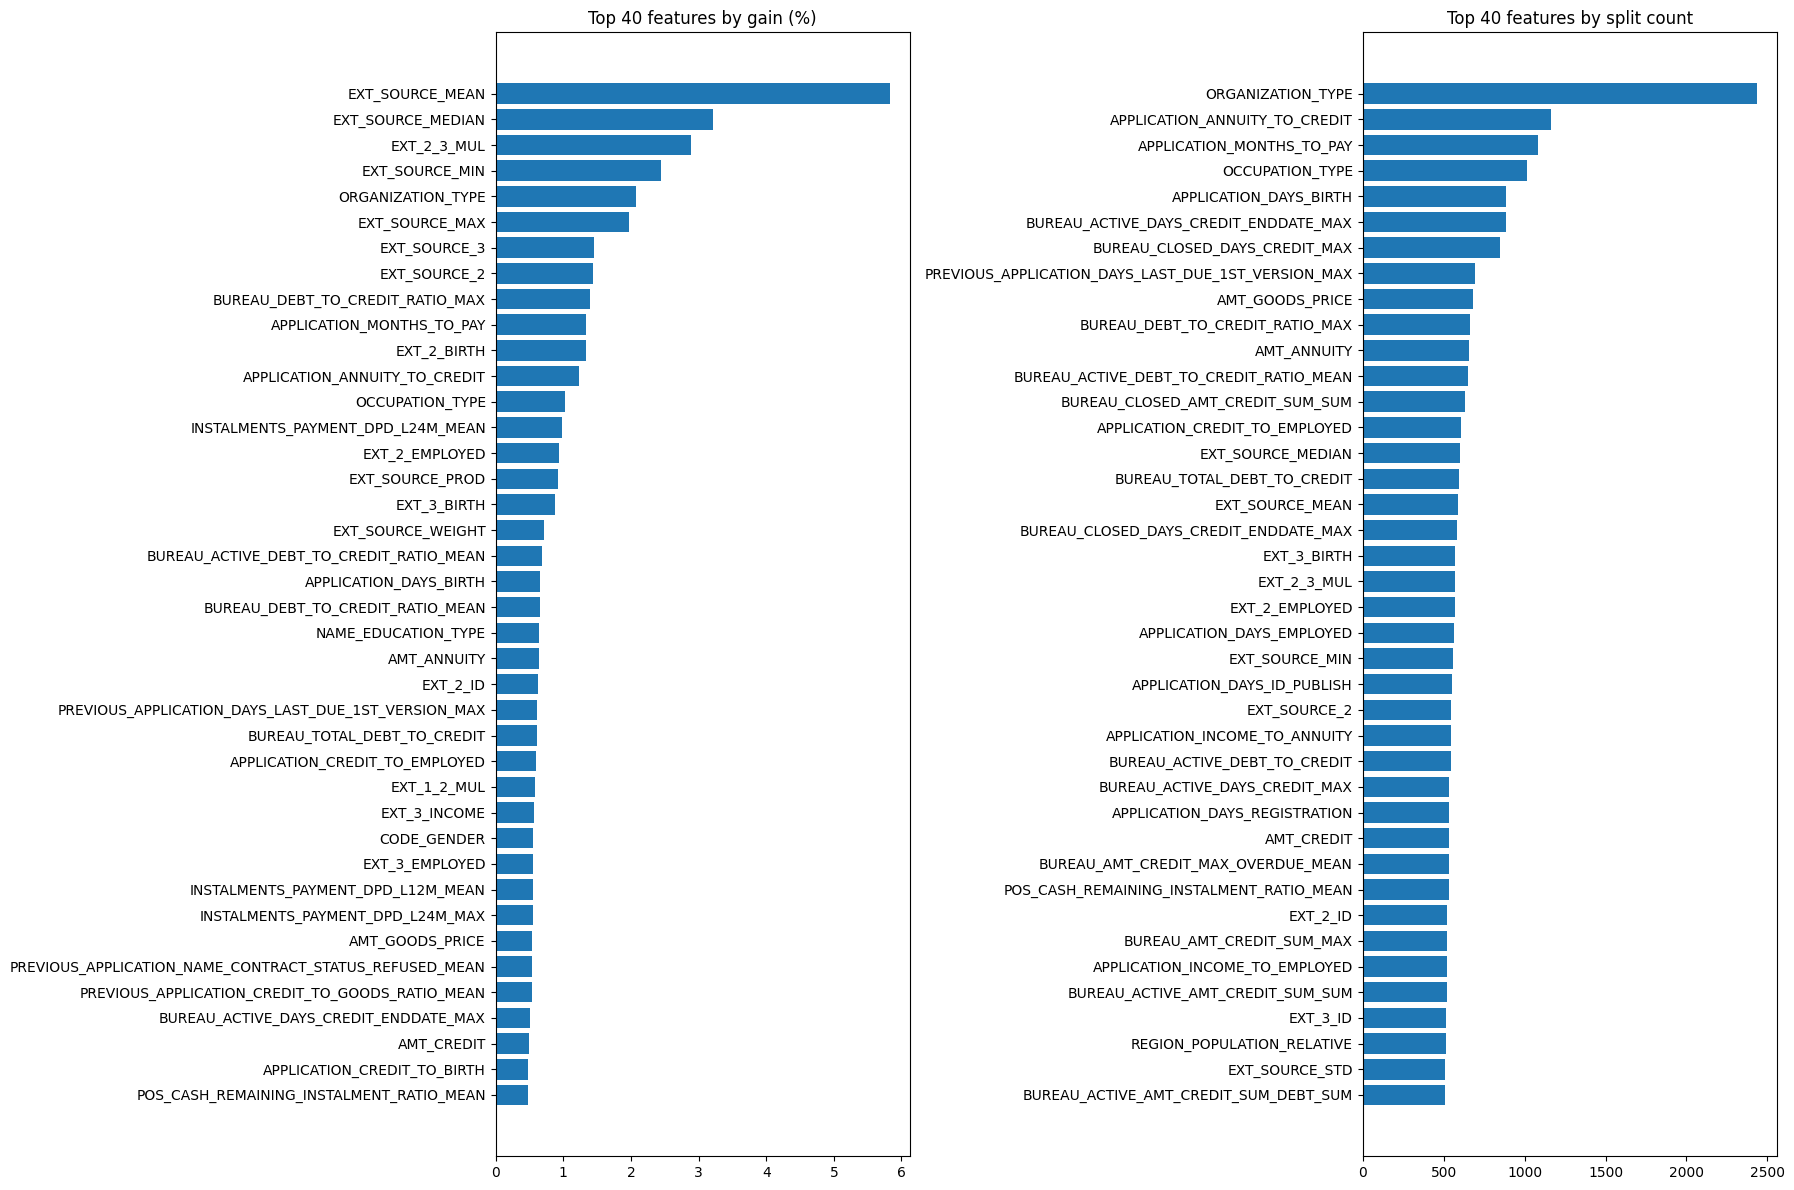

In [24]:
TOP_N = 40
fig, axes = plt.subplots(1, 2, figsize = (18, 12))

top_gain = imp.head(TOP_N)
axes[0].barh(top_gain['feature'][::-1], top_gain['gain_pct'][::-1])
axes[0].set_title(f'Top {TOP_N} features by gain (%)')

top_split = imp.sort_values('split', ascending = False).head(TOP_N)
axes[1].barh(top_split['feature'][::-1], top_split['split'][::-1])
axes[1].set_title(f'Top {TOP_N} features by split count')

plt.tight_layout()
plt.show()

## 7.2 SHAP Values
Each fold model explains a sample of **its own validation fold** (unseen data), then the folds are stacked.
SHAP values are computed with LightGBM's native `pred_contrib=True` (exact TreeSHAP, handles categorical columns), and wrapped in `shap.Explanation` for plotting. Values are in log-odds.

In [25]:
SHAP_ROWS_PER_FOLD = 4000
rng = np.random.RandomState(42)

shap_parts, data_parts, base_values = [], [], []
for model, val_idx in zip(fold_models, fold_val_idx):
    sample_idx = rng.choice(val_idx, size = min(SHAP_ROWS_PER_FOLD, len(val_idx)), replace = False)
    X_s = X_full.iloc[sample_idx]

    contrib = model.booster_.predict(X_s, num_iteration = model.best_iteration_, pred_contrib = True)
    shap_parts.append(contrib[:, :-1])   # last column = expected value (bias)
    base_values.append(contrib[:, -1])
    data_parts.append(X_s)

X_shap = pd.concat(data_parts)
shap_values = np.vstack(shap_parts)

# Categorical -> codes so the beeswarm can color points
X_shap_plot = X_shap.copy()
for col in X_shap_plot.select_dtypes(include = 'category').columns:
    X_shap_plot[col] = X_shap_plot[col].cat.codes.replace(-1, np.nan)

explanation = shap.Explanation(
    values = shap_values,
    base_values = np.concatenate(base_values),
    data = X_shap_plot.to_numpy(dtype = float),
    feature_names = list(X_full.columns)
)
print("SHAP matrix:", shap_values.shape)

KeyboardInterrupt: 

In [ ]:
shap_imp = pd.DataFrame({
    'feature': X_full.columns,
    'mean_abs_shap': np.abs(shap_values).mean(axis = 0)
}).sort_values('mean_abs_shap', ascending = False).reset_index(drop = True)

# Compare SHAP ranking vs gain ranking
compare = shap_imp.merge(imp[['feature', 'gain_pct']], on = 'feature')
compare['shap_rank'] = np.arange(1, len(compare) + 1)
compare['gain_rank'] = compare['gain_pct'].rank(ascending = False).astype(int)
display(compare.head(30))
print("Features with mean |SHAP| == 0:", (shap_imp['mean_abs_shap'] == 0).sum())

,feature,mean_abs_shap,gain_pct,shap_rank,gain_rank
0,EXT_SOURCE_MEDIAN,0.131489,6.043762,1,1
1,CODE_GENDER,0.096223,0.476819,2,45
2,AMT_ANNUITY,0.092033,0.952591,3,15
3,PREVIOUS_APPLICATION_DAYS_LAST_DUE_1ST_VERSION...,0.088847,0.894434,4,17
4,EXT_SOURCE_MEAN,0.087702,4.498471,5,2
5,BUREAU_DEBT_TO_CREDIT_RATIO_MAX,0.084660,1.693367,6,8
6,APPLICATION_MONTHS_TO_PAY,0.081481,2.081921,7,5
7,NAME_EDUCATION_TYPE,0.078142,0.753790,8,22
8,EXT_SOURCE_MIN,0.074487,3.046139,9,3
9,INSTALMENTS_PAYMENT_DPD_L24M_MEAN,0.072054,1.448711,10,9


Features with mean |SHAP| == 0: 60


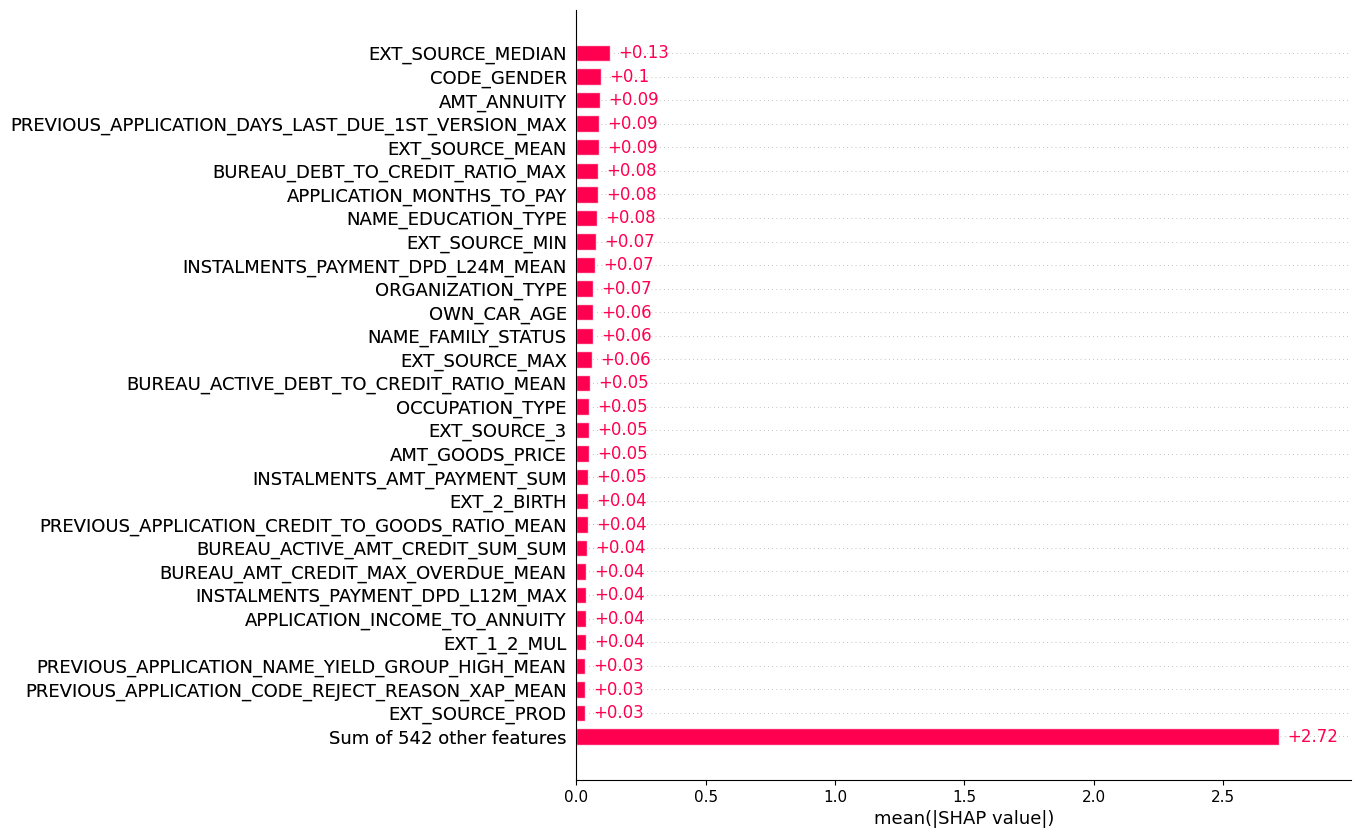

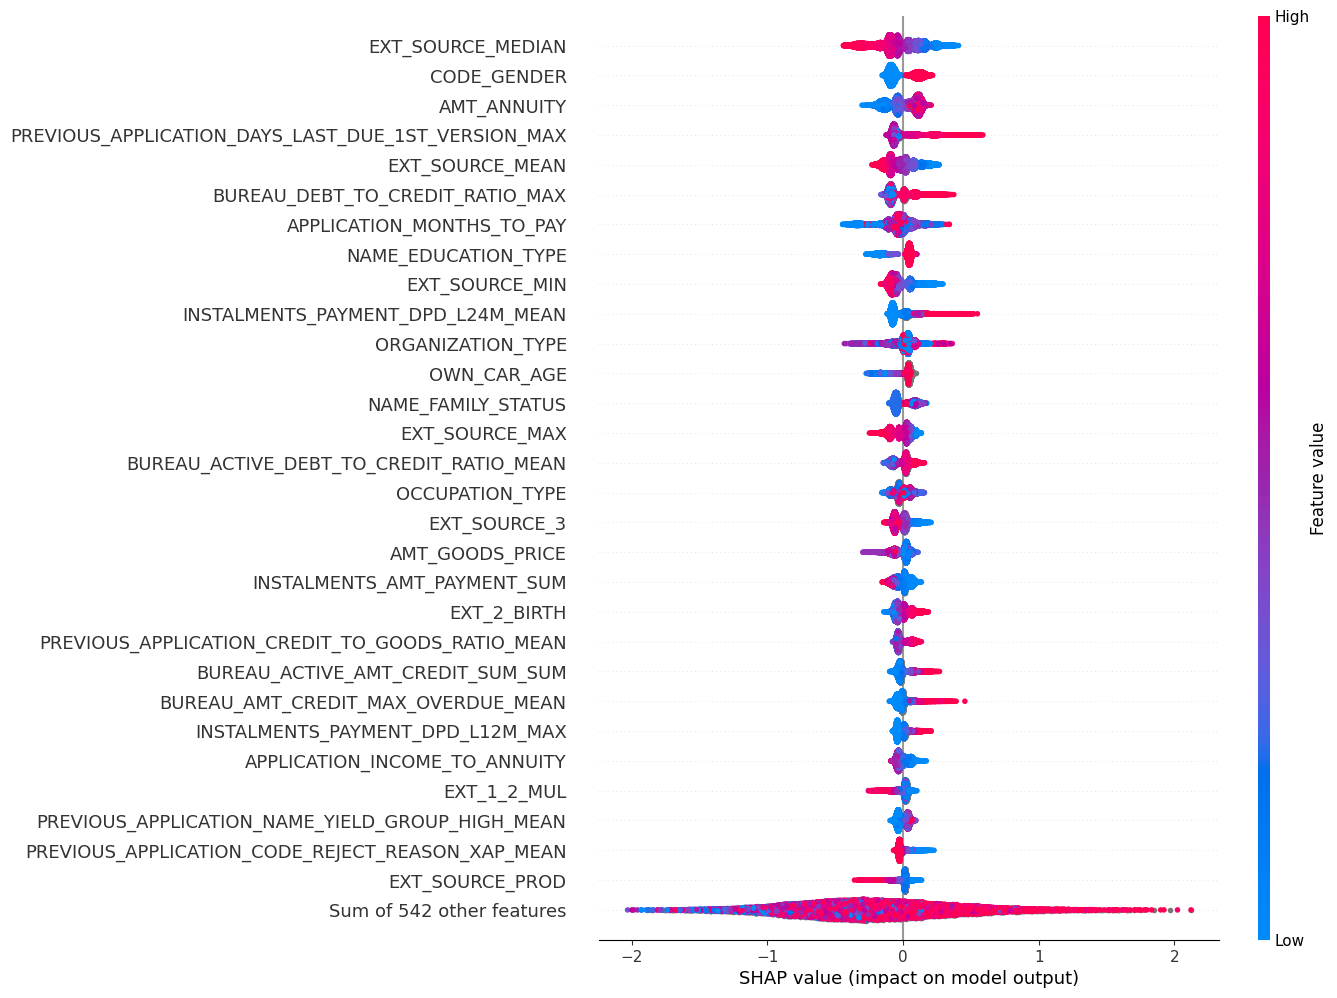

In [ ]:
# Global importance + direction of effect
shap.plots.bar(explanation, max_display = 30, show = False)
plt.gcf().set_size_inches(10, 10)
plt.show()

shap.plots.beeswarm(explanation, max_display = 30, show = False)
plt.gcf().set_size_inches(10, 12)
plt.show()

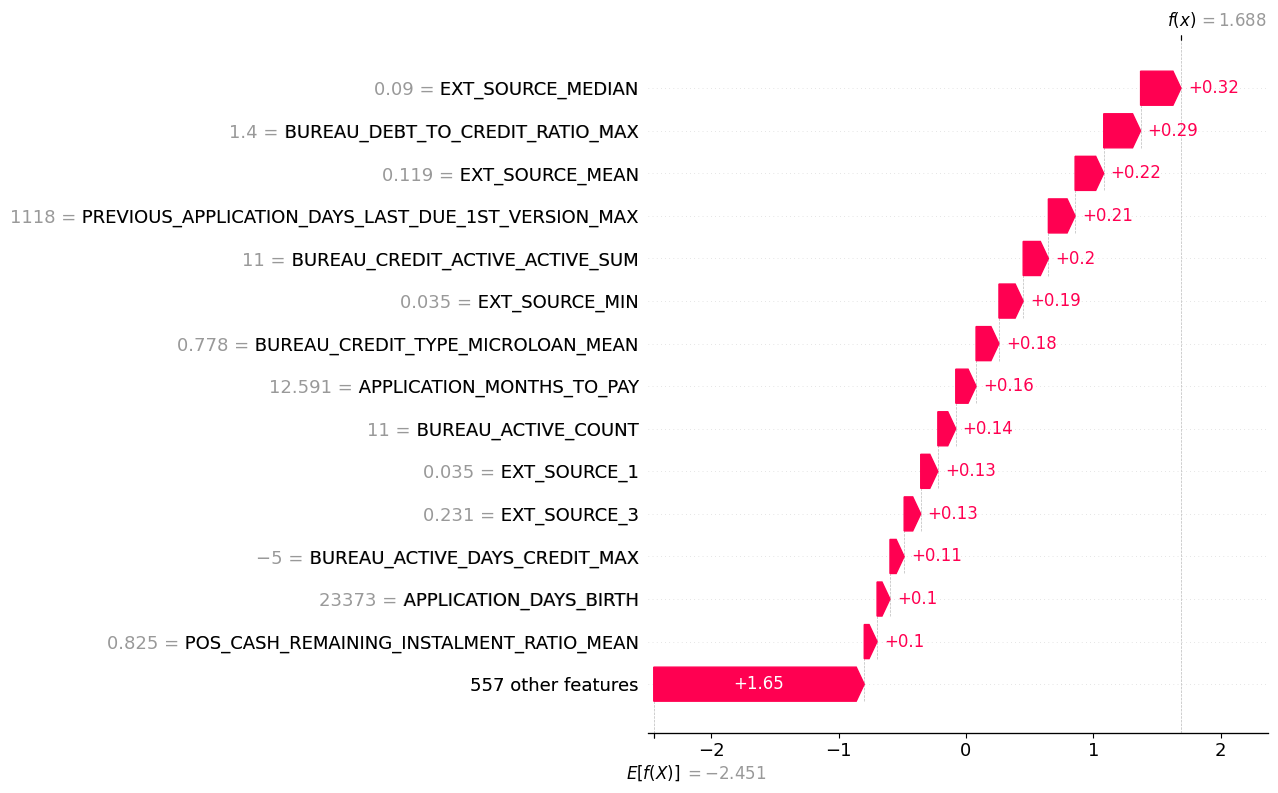

In [ ]:
# Local explanation: the highest-risk applicant in the SHAP sample
i = int(np.argmax(explanation.values.sum(axis = 1) + explanation.base_values))
shap.plots.waterfall(explanation[i], max_display = 15, show = False)
plt.show()

## 7.3 Feature Selection Check
Drop features with low mean |SHAP| and re-run the same 5-fold CV to see whether AUC holds or improves.
Same model params, same folds -> fair comparison with the full-feature OOF AUC.

In [ ]:
def cv_auc(features, seed = 42):
    skf = StratifiedKFold(n_splits = N_SPLITS, shuffle = True, random_state = seed)
    oof = np.zeros(len(X_full))
    for tr_idx, val_idx in skf.split(X_full, y_full):
        model = clone(lgbm).set_params(random_state = seed, objective = "binary", metric = "auc")
        model.fit(
            X_full.iloc[tr_idx][features], y_full.iloc[tr_idx],
            eval_set = [(X_full.iloc[val_idx][features], y_full.iloc[val_idx])],
            eval_metric = "auc",
            callbacks = [lgb.early_stopping(200, first_metric_only = True, verbose = False)]
        )
        oof[val_idx] = model.predict_proba(X_full.iloc[val_idx][features])[:, 1]
    return roc_auc_score(y_full, oof)


print(f"All {X_full.shape[1]} features: OOF AUC = {oof_auc:.5f}")

# Thresholds by number of kept features (ranked by mean |SHAP|)
results = []
non_zero_features = X_full.shape[1] - (imp['gain'] == 0).sum()
for keep in [non_zero_features]:
    feats = shap_imp['feature'].head(keep).tolist()
    auc = cv_auc(feats)
    results.append({'n_features': keep, 'oof_auc': auc, 'delta': auc - oof_auc})
    print(f"Top {keep} features: OOF AUC = {auc:.5f} ({auc - oof_auc:+.5f})")

display(pd.DataFrame(results))

All 571 features: OOF AUC = 0.79705


c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is depreca

Top 511 features: OOF AUC = 0.79727 (+0.00022)


,n_features,oof_auc,delta
0,511,0.797272,0.000224
